# 03 — Time-Aware & Session-Aware Feature Engineering

**Project:** AI-Based IoT Sensor Anomaly Detection (ESP32 + DHT11)  
**Shared Module:** [`features/feature_engine.py`](../../features/feature_engine.py)  

Why this upgrade replaced the legacy 14-feature pipeline:
1. **Drift invariance:** Drops raw absolute `(temperature, humidity)` from `MODEL_FEATURE_COLS` so a warmer drier room (e.g. `29.6 C / 53.7%` vs `25.7 C / 61.4%`) does not trigger continuous false alarms.
2. **Causal rate-gated Cauchy EWMA (`_compute_gated_ewma_baseline`):** Adapts across diurnal ambient shifts (`halflife=2400s`) while halting baseline updates during sustained anomalies so post-recovery tails do not false-trigger.
3. **Time-based rolling windows (`10s`, `30s`) inside `session_id` boundaries (`gap > 10s`)** and orthogonal **12-feature vector**.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'config.yaml').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config import config
print(f'Project root: {PROJECT_ROOT}')
import matplotlib.pyplot as plt
import pandas as pd
from features.feature_engine import MODEL_FEATURE_COLS, build_features, default_feature_params

print('Default feature parameters:', default_feature_params())
print(f'MODEL_FEATURE_COLS ({len(MODEL_FEATURE_COLS)}):', MODEL_FEATURE_COLS)

Project root: c:\Users\Avinash Reddy\OneDrive\Desktop\Iot anomaly detection
Default feature parameters: {'gap_threshold': 10.0, 'roll_min': 2, 'short_window_sec': 10, 'long_window_sec': 30, 'ewma_halflife_sec': 2400, 'ewma_macro_gap_sec': 1800}
MODEL_FEATURE_COLS (12): ['temp_ewma_residual', 'hum_ewma_residual', 'temp_ewma_abs_residual', 'hum_ewma_abs_residual', 'ewma_joint_norm', 'temp_rate', 'hum_rate', 'rate_joint_norm', 'temp_rolling_std_10s', 'hum_rolling_std_10s', 'temp_jitter_10s', 'hum_jitter_10s']


## Inspect Regenerated `features_v2/` Feature Matrices
Verify shapes, zero NaNs, and session continuity across `normal`, `pilot`, `test`, and `eval_suite`.

In [2]:
feat_dir = config.features_dir
for name in ['normal', 'pilot', 'test', 'eval_suite']:
    full_df = pd.read_csv(feat_dir / f'{name}_features_full.csv')
    mat_df = pd.read_csv(feat_dir / f'{name}_features.csv')
    nans = int(mat_df.isna().sum().sum())
    print(f'{name:11s} | full_shape={str(full_df.shape):12s} | matrix_shape={str(mat_df.shape):11s} | '
          f'sessions={full_df.session_id.nunique():2d} | NaNs={nans}')

normal      | full_shape=(34374, 21)  | matrix_shape=(34374, 12) | sessions= 9 | NaNs=0
pilot       | full_shape=(3084, 21)   | matrix_shape=(3084, 12)  | sessions= 3 | NaNs=0
test        | full_shape=(55, 22)     | matrix_shape=(55, 12)    | sessions= 1 | NaNs=0
eval_suite  | full_shape=(1947, 23)   | matrix_shape=(1947, 12)  | sessions= 3 | NaNs=0


## Visualizing Causal EWMA Residuals & Joint Norm on Pilot Event 1
Compare raw temperature/humidity against the drift-aware EWMA residuals across the `23:09:38 -> 23:40:28` pilot event.

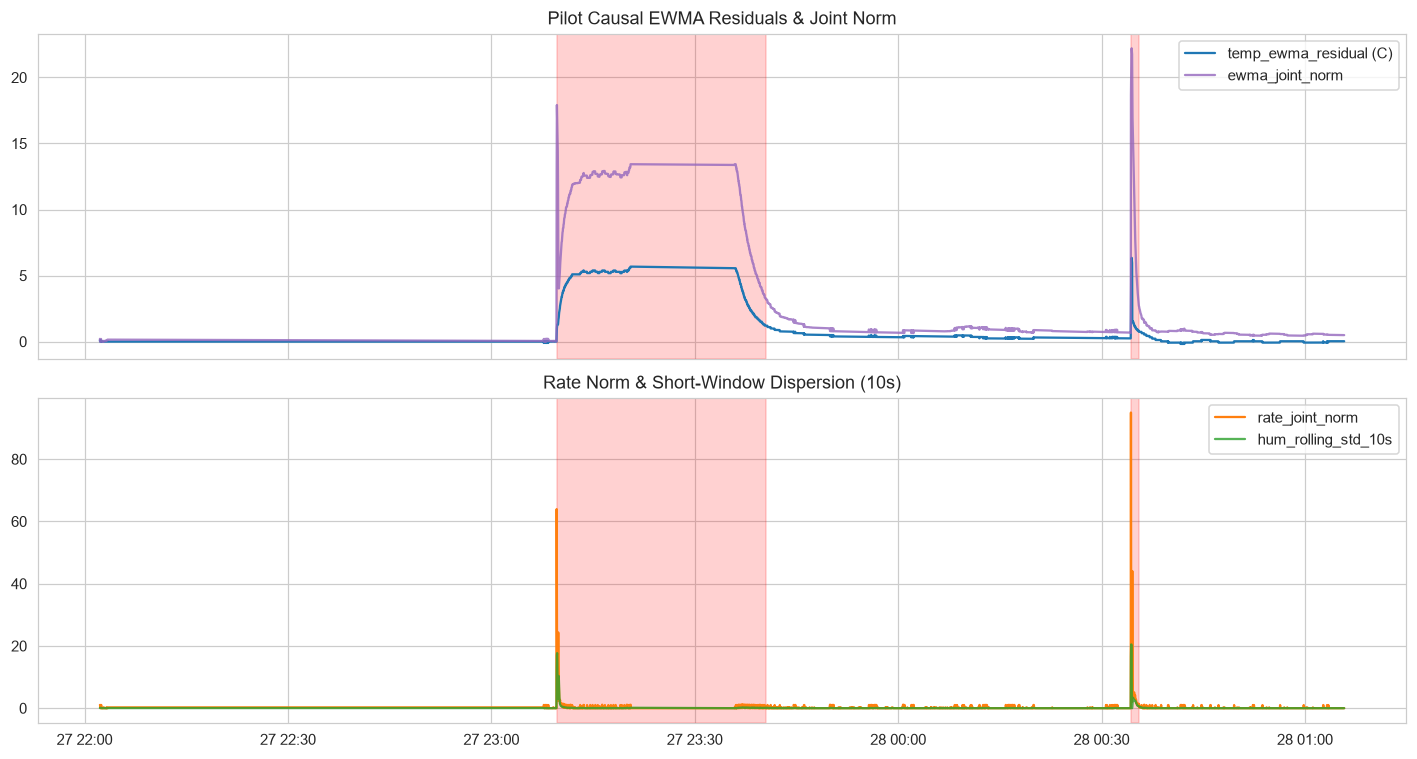

In [3]:
pilot_feat = pd.read_csv(config.features_dir / 'pilot_features_full.csv', parse_dates=['timestamp'])
ann = pd.read_csv(config.processed_dir / 'pilot_event_annotations.csv', parse_dates=['start_time', 'end_time'])

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(pilot_feat['timestamp'], pilot_feat['temp_ewma_residual'], label='temp_ewma_residual (C)', color='tab:blue')
axes[0].plot(pilot_feat['timestamp'], pilot_feat['ewma_joint_norm'], label='ewma_joint_norm', color='tab:purple', alpha=0.8)
for _, r in ann.iterrows():
    axes[0].axvspan(r['start_time'], r['end_time'], color='red', alpha=0.18)
axes[0].set_title('Pilot Causal EWMA Residuals & Joint Norm')
axes[0].legend()

axes[1].plot(pilot_feat['timestamp'], pilot_feat['rate_joint_norm'], label='rate_joint_norm', color='tab:orange')
axes[1].plot(pilot_feat['timestamp'], pilot_feat['hum_rolling_std_10s'], label='hum_rolling_std_10s', color='tab:green', alpha=0.8)
for _, r in ann.iterrows():
    axes[1].axvspan(r['start_time'], r['end_time'], color='red', alpha=0.18)
axes[1].set_title('Rate Norm & Short-Window Dispersion (10s)')
axes[1].legend()

plt.tight_layout()
plt.show()